#Data exploration - advanced.
Author: Bartosz Kołacz.

Source: https://www.kaggle.com/datasets/osmi/mental-health-in-tech-survey

Dataset: survey.csv

This dataset is from a 2014 survey that measures attitudes towards mental health and frequency of mental health disorders in the tech workplace.

**1. Imports, data upload and cleaning up**

Let's begin with adding necessary libraries and with loading of the dataset from survey.csv.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('survey.csv')
df.head(5)

,Timestamp,Age,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,...,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
0,2014-08-27 11:29:31,37,Female,United States,IL,NaN,No,Yes,Often,6-25,...,Somewhat easy,No,No,Some of them,Yes,No,Maybe,Yes,No,NaN
1,2014-08-27 11:29:37,44,M,United States,IN,NaN,No,No,Rarely,More than 1000,...,Don't know,Maybe,No,No,No,No,No,Don't know,No,NaN
2,2014-08-27 11:29:44,32,Male,Canada,NaN,NaN,No,No,Rarely,6-25,...,Somewhat difficult,No,No,Yes,Yes,Yes,Yes,No,No,NaN
3,2014-08-27 11:29:46,31,Male,United Kingdom,NaN,NaN,Yes,Yes,Often,26-100,...,Somewhat difficult,Yes,Yes,Some of them,No,Maybe,Maybe,No,Yes,NaN
4,2014-08-27 11:30:22,31,Male,United States,TX,NaN,No,No,Never,100-500,...,Don't know,No,No,Some of them,Yes,Yes,Yes,Don't know,No,NaN


In the survey, the gender field was an open text field rather than a multiple choice list. That resulted in the gender column, containing multiple records that describe the same value, what was shown below. Firstly, I grouped it around "male", "female" and "other".

In [3]:
df['Gender'].value_counts().head(10)

,count
Gender,
Male,615
male,206
Female,121
M,116
female,62
F,38
m,34
f,15
Make,4


In [4]:
def clean_gender(gender):
    gender = str(gender).lower().strip()
    if any(g in gender for g in ['male', 'm', 'cis male', 'mal', 'maile', 'msle']):
        if 'female' in gender or 'trans' in gender and 'female' in gender:
            return 'Female'
        return 'Male'
    elif any(g in gender for g in ['female', 'f', 'woman', 'femake', 'cis female']):
        return 'Female'
    else:
        return 'Other'

df['Gender'] = df['Gender'].apply(clean_gender)

I checked if some data was missing. As we can see, almost half of responders skipped the answear in field "state", so i decide to delete it from my dataset.  

In [5]:
print("Rows and columns:", df.shape)
print("Column names:", df.columns.tolist())
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
}))

Rows and columns: (1259, 27)
Column names: ['Timestamp', 'Age', 'Gender', 'Country', 'state', 'self_employed', 'family_history', 'treatment', 'work_interfere', 'no_employees', 'remote_work', 'tech_company', 'benefits', 'care_options', 'wellness_program', 'seek_help', 'anonymity', 'leave', 'mental_health_consequence', 'phys_health_consequence', 'coworkers', 'supervisor', 'mental_health_interview', 'phys_health_interview', 'mental_vs_physical', 'obs_consequence', 'comments']


,dtype,missing_values
Timestamp,object,0
Age,int64,0
Gender,object,0
Country,object,0
state,object,515
self_employed,object,18
family_history,object,0
treatment,object,0
work_interfere,object,264
no_employees,object,0


In [6]:
df = df.drop(columns=['state'])

In the end, I removed "age" beyond the range 18-100 years old.

In [7]:
df = df[(df['Age'] >= 18) & (df['Age'] <= 100)]

**2. Introduction**

Data dictionary:

| Column name | Data type | Description |
|---|---|---|
| age | int | Employee age |
| gender | text | Employee gender |
| country | text | Country of residence |
| self_employed | text | Employment status (self employment) |
| family_history | text | History of mental illness in the family of employee |
| treatment | text | Whether the employee sought mental health treatment |
| work_interfere | text | Whether mental health issues interfered work productivity |
| no_employees | text | Size of the company |
| remote_work | text | Wheteher employee worked remotely |
| tech_company | text | Whether the employer is primarily a tech/IT company |
| benefit | text | Help from the employeer |
| care_options | text | Employee awareness about mental healthcare options |
| wellness_program | text | Whether employer provided mental health promotion programs inside company |
| seek_help | text |  Whether the employer provides resources and education on how to seek help |
| anonymity | text | Perception of anonymity when using employer provided mental health resources |
| leave | text | Whether employee has possibility to take leave for mental health reasons. |
| mental_health_consequence | text | Fear of negative career consequences affiliated to mental healt problems |
| phys_health_consequence | text | Fear of negative career consequences affiliated to physical healt problems |
| coworkers | text | Support from coworkers |
| supervisor | text | Support from supervisor |


As we can see in the dictionary above, the only column with numerical datatype is field "age". The other fields, are text, it means "object". I groupped them in separate categories:

numerical_vars - for numerical datatypes (in our dataset only "Age"

categorical_vars- for text fields (other)

In [8]:
numerical_vars = ['Age']
categorical_vars = df.select_dtypes(include=['object']).columns

Data summary:

In [9]:
df['Age'].describe().round(2)

,Age
count,1251.00
mean,32.08
std,7.29
min,18.00
25%,27.00
50%,31.00
75%,36.00
max,72.00


In [10]:
for col in categorical_vars:
    if col != "Timestamp" and col != "comments":
        print(f"\n--- {col} ---")
        display(df[col].value_counts(dropna=False).head(10))


--- Gender ---


,count
Gender,
Male,996
Female,245
Other,10



--- Country ---


,count
Country,
United States,746
United Kingdom,184
Canada,72
Germany,45
Netherlands,27
Ireland,27
Australia,21
France,13
India,10



--- self_employed ---


,count
self_employed,
No,1091
Yes,142
NaN,18


... (36 outputs left out)


--- mental_vs_physical ---


,count
mental_vs_physical,
Don't know,574
Yes,339
No,338



--- obs_consequence ---


,count
obs_consequence,
No,1070
Yes,181


Above, we can see full summary of data in each column. I observed that:

1. About 80% of the responders are males.

2. The mean age of reponders is 32 years old, and the median is 31 years old. The oldest participant was 72 years old.

3. The proportion of employees who sought mental health support and those who did not is nearly equal, at 50/50.

4. About half of responders are affraid of work consequnces over their mental health (mental_health_consequence) but psychical consequences are not treated the same (phys_health_consequences).

5. Mental health issues affect the qulity of the employees work. Most answers are: Sometimes or Often (work_interfere).

**3. Dataset on graphs**

Let's move to actual data analysis. I previously cleaned up the dataset. Let's have a look on collected data on charts. I began my analysys with sight at the distribution of key variables.

Age distribution:

Histogram in below shows that vast majority of the responders belong to the 25-35 years old range. It indicates that the survey results are shown from mostly young employees perspective in IT branch.

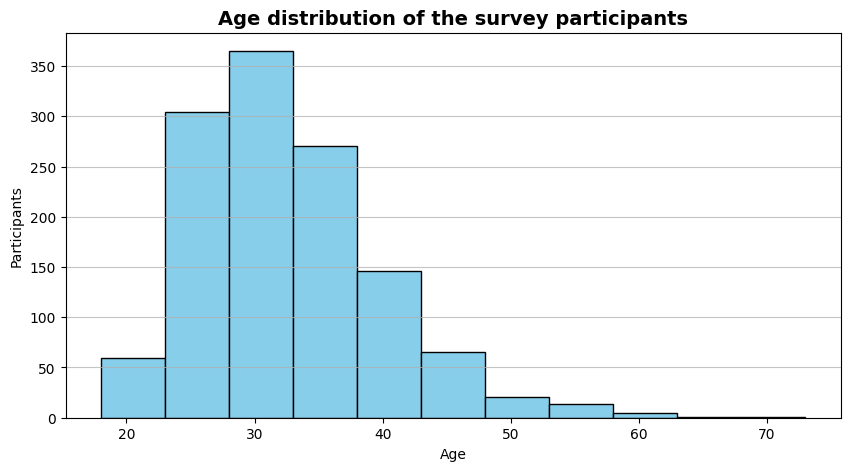

In [23]:
plt.figure(figsize=(10, 5))
plt.hist(df['Age'].dropna(), bins=range(int(df['Age'].min()), int(df['Age'].max()) + 5, 5), edgecolor='black', color='skyblue')
plt.title('Age distribution of the survey participants',fontsize=14, fontweight='bold')
plt.xlabel('Age')
plt.ylabel('Participants')
plt.grid(axis='y', alpha=0.75)
plt.show()

Gender distribution:

Donut chart below indicates that vast majority of the responders are males. That fact reflects demographic trend towards IT.

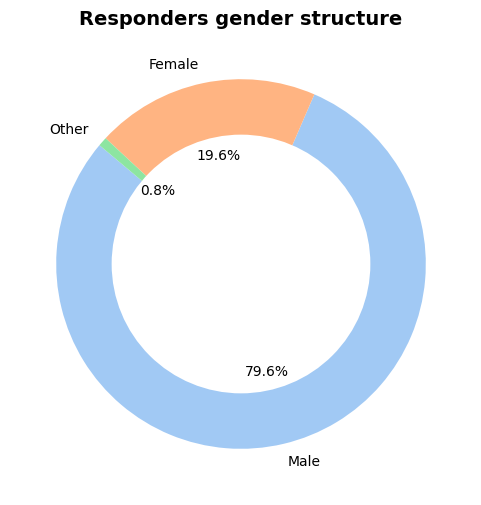

In [21]:
gender_counts = df['Gender'].value_counts()
colors = sns.color_palette('pastel', len(gender_counts)) # seaborn color palette

plt.figure(figsize=(6, 6))
plt.pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', startangle=140, colors=colors)
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)
plt.title('Responders gender structure', fontsize=14, fontweight='bold')
plt.show()

Did the responders seek treatment?

Answer to that question is almost perfectly balanced, half of the responders sought for the help, other half did not.

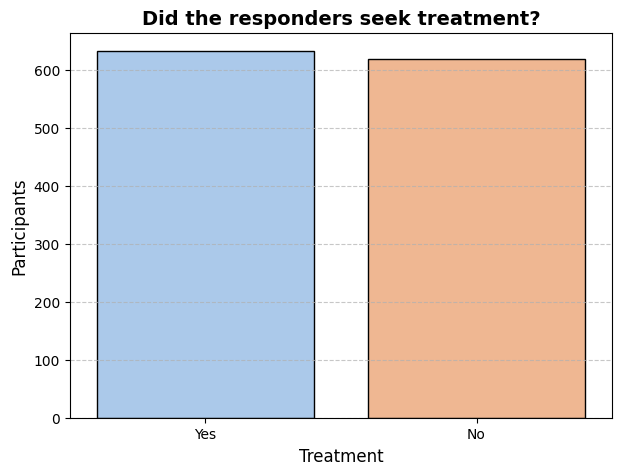

In [25]:
colors = sns.color_palette('pastel', len(df['treatment'].unique()))

plt.figure(figsize=(7, 5))
sns.countplot(
    x='treatment',
    hue = 'treatment',
    data=df,
    palette=colors,
    order=df['treatment'].value_counts().index,
    edgecolor='black'
)
plt.title('Did the responders seek treatment?', fontsize=14, fontweight='bold')
plt.xlabel('Treatment', fontsize=12)
plt.ylabel('Participants', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

How often mental health interferes with work

The histogram below shows that mental health related issues significantly impact on productivity. Only about 200 responders of 1251 have never expierienced difficulties due to psychological problems.

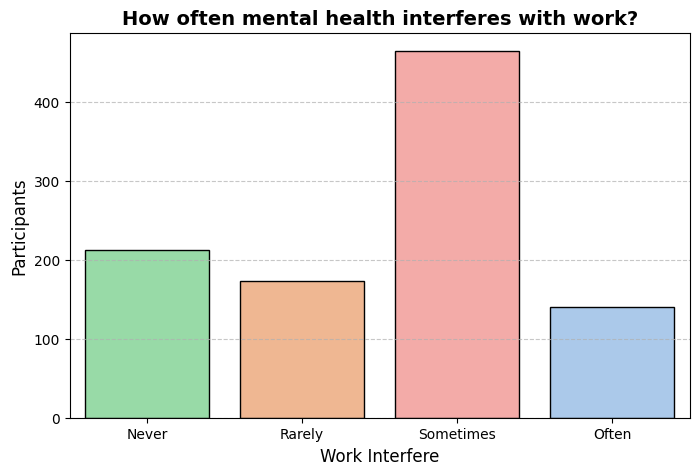

In [27]:
plt.figure(figsize=(8, 5))
sns.countplot(
    x='work_interfere',
    hue='work_interfere',
    data=df,
    palette='pastel',
    order=['Never', 'Rarely', 'Sometimes', 'Often'],
    edgecolor='black',
    legend=False
)
plt.title('How often mental health interferes with work?', fontsize=14, fontweight='bold')
plt.xlabel('Work Interfere', fontsize=12)
plt.ylabel('Participants', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Company size distribution

The size distribution indicates that participants are relatively evenly distributed, from small startups to big tech IT companies. That fact guarantee that data are relatively objective.

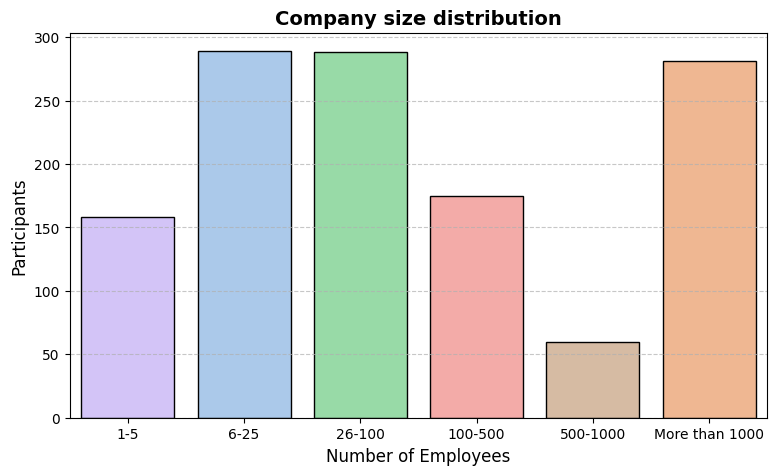

In [29]:
plt.figure(figsize=(9, 5))
sns.countplot(
    x='no_employees',
    hue='no_employees',
    data=df,
    palette='pastel',
    order=['1-5', '6-25', '26-100', '100-500', '500-1000', 'More than 1000'],
    edgecolor='black',
    legend=False
)
plt.title('Company size distribution', fontsize=14, fontweight='bold')
plt.xlabel('Number of Employees', fontsize=12)
plt.ylabel('Participants', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

**4. Data analysis**

While preparing the graphs for section 3, I identified several interesting questions, that I intend to answer in my further work:

*   Does size of the company affects on beneficital mental health support from employer?
*   What is relationship between taking medical leave and seeking for treatment?
*   What is consider to be worse, mental health issues or physical health issues?
*   Do self employed workers have same opportunity to receive help like big company workers?
*   How work place atmosphere affects work interferences toward mental health?
*   In IT industry, are men or women more likely to seek psychological help?



**Size of the company vs Benefits**

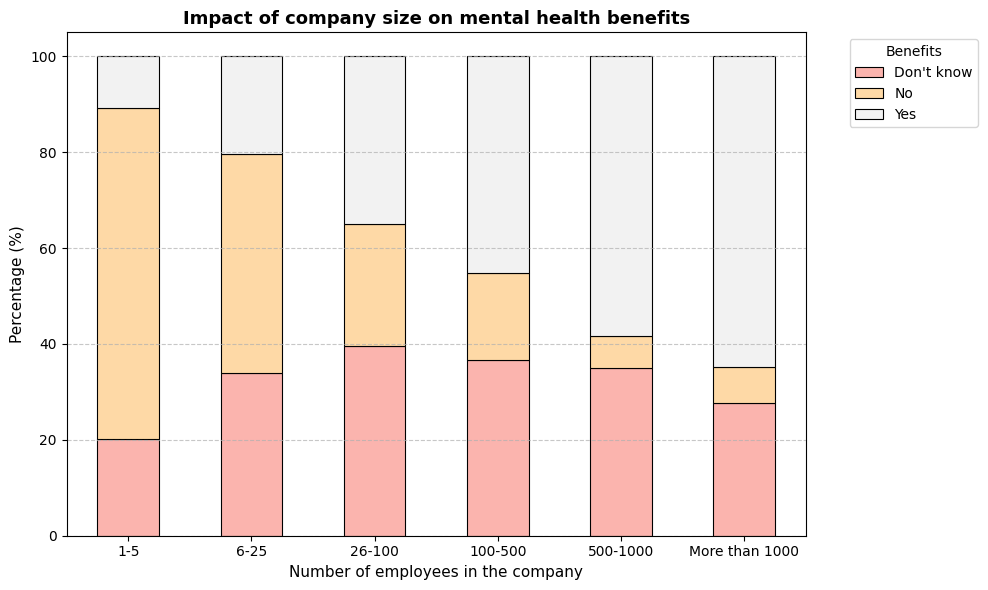

In [32]:
ct = pd.crosstab(df['no_employees'], df['benefits'], normalize='index') * 100
size_order = ['1-5', '6-25', '26-100', '100-500', '500-1000', 'More than 1000']
existing_order = [x for x in size_order if x in ct.index]
if existing_order:
    ct = ct.loc[existing_order]

ax = ct.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    colormap='Pastel1',
    edgecolor='black',
    linewidth=0.8
)

plt.title('Impact of company size on mental health benefits', fontsize=13, fontweight='bold')
plt.xlabel('Number of employees in the company', fontsize=11)
plt.ylabel('Percentage (%)', fontsize=11)
plt.legend(title='Benefits', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The size matters. As we can see on a "Impact of company size on mental health benefits" graph, there is strong corelation between company size and distribution of the answers. The bigger amount of employees, the more benefits they receive. As the number of employees increases, the results tend to "reverse" (take a look on yellow and white parts on a graph). That fact is very positive, becasue awareness among big IT tech companies employers really care about their employees.

What is more, independently from the company size, big part of workers do not know about entitled benefits to them. Red part of the graph is ALMOST evenly distributed for about 30%. That indicates internal communicating problem.

**Leave vs Treatment**

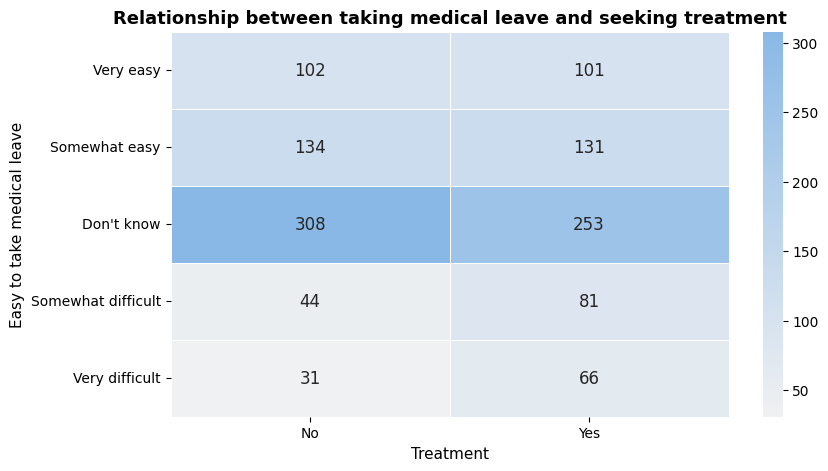

In [34]:
leave_order = ['Very easy', 'Somewhat easy', "Don't know", 'Somewhat difficult', 'Very difficult']
ct = pd.crosstab(df['leave'], df['treatment'])
existing_order = [x for x in leave_order if x in ct.index]
if existing_order:
    ct = ct.loc[existing_order]

pastel_cmap = sns.light_palette("#8ab8e6", as_cmap=True)

plt.figure(figsize=(9, 5))
sns.heatmap(
    ct,
    annot=True,
    fmt="d",
    cmap=pastel_cmap,
    cbar=True,
    linewidths=.5,
    annot_kws={"size": 12}
)

plt.title('Relationship between taking medical leave and seeking treatment', fontsize=13, fontweight='bold')
plt.xlabel('Treatment', fontsize=11)
plt.ylabel('Easy to take medical leave', fontsize=11)
plt.show()

Heatmap above shows us some interesting corelation between simpliness of taking medical leave and seeking treatment.

For companies where taking a leave is relatively simple (Very easy and Somewhat easy), employees tendencies toward seeking mental help is evenly distributed. However for environments where getting leave is difficult, employees that are seeking for help appear to be considerably twice as high (take a look on Somewhat difficult and Very difficult). That lead me to propose a hipotese:  workplaces where taking medical leave is more difficult may be associated with more stressful working conditions, which could, in turn, contribute to a greater need for mental health support among employees.

**Mental health consequences vs Physical health consequences**

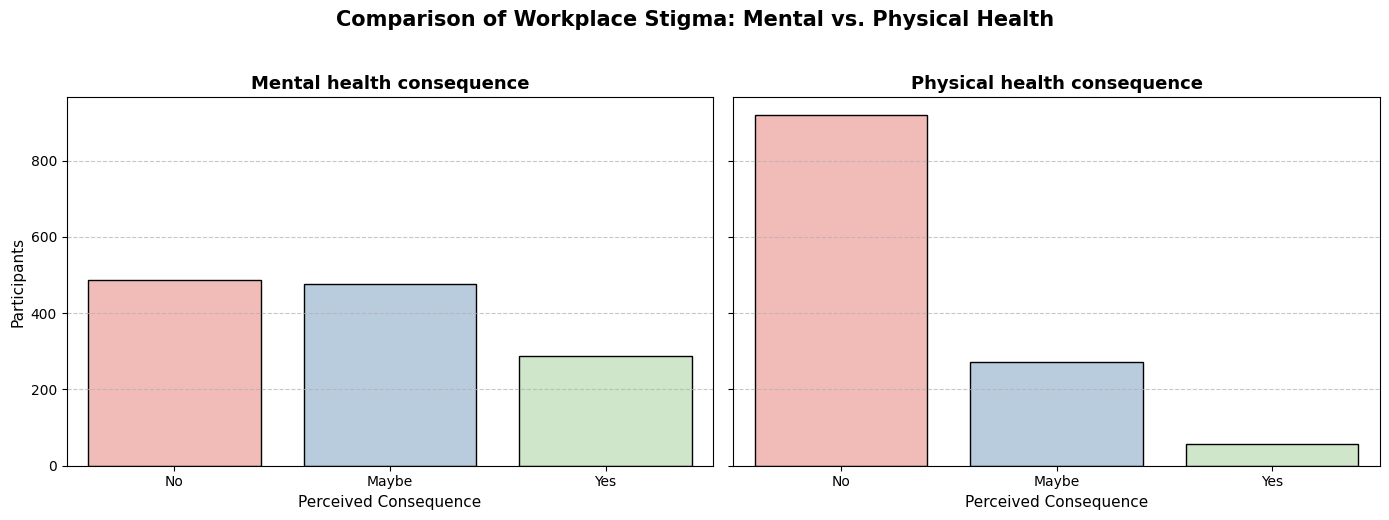

In [47]:
consequence_order = ['No', 'Maybe', 'Yes']
palette_dict = {
    'No': '#fbb4ae',
    'Maybe': '#b3cde3',
    'Yes': '#ccebc5'
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

sns.countplot(
    x='mental_health_consequence',
    hue='mental_health_consequence',
    data=df,
    palette=palette_dict,
    order=consequence_order,
    edgecolor='black',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Mental health consequence', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Perceived Consequence', fontsize=11)
axes[0].set_ylabel('Participants', fontsize=11)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

sns.countplot(
    x='phys_health_consequence',
    hue='phys_health_consequence',
    data=df,
    palette=palette_dict,
    order=consequence_order,
    edgecolor='black',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Physical health consequence', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Perceived Consequence', fontsize=11)
axes[1].set_ylabel('')
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.suptitle('Comparison of Workplace Stigma: Mental vs. Physical Health', fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

The histogram above, shows us tendency that employees are affraid more about mental health issue consequences rather then about pshyical health issue conseqences. Frankly, it was surprising fact for me becasuse I believed that todays society is more progressice and open toward mental health issues.

However, data reveals that despite of awereness, stigmatisation remains. Propably, physical health struggles are easier to accept for society, so people avoid seeking for psychological help.



**Care options vs Self employment**

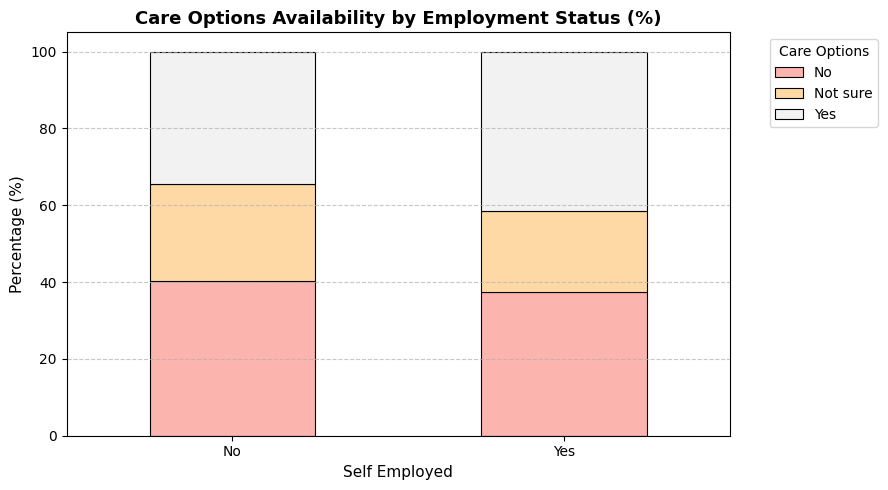

In [48]:
ct = pd.crosstab(df['self_employed'], df['care_options'], normalize='index') * 100

ax = ct.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5),
    colormap='Pastel1',
    edgecolor='black',
    linewidth=0.8
)

plt.title('Care Options Availability by Employment Status (%)', fontsize=13, fontweight='bold')
plt.xlabel('Self Employed', fontsize=11)
plt.ylabel('Percentage (%)', fontsize=11)
plt.legend(title='Care Options', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Frankly, that plot was the most surprising for me personaly. It is the first plot where I can not see any corelation between data.

Self employmnet in IT industry is very popular. Freelancering become so attractive becasue of flexible working schedule or simpliness of changing speciality.

As we can see above, it does not matter, whether participant was employed in tech company or was freelancer. The percentage of responces is almost the same.

**Coworker and supervior support vs Work interference**

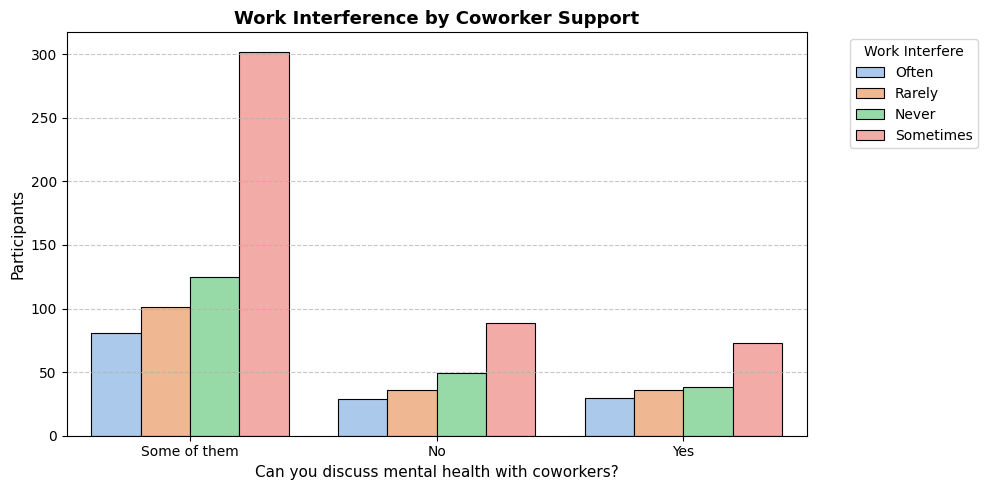

In [52]:
sns.countplot(
    x='coworkers',
    hue='work_interfere',
    data=df,
    palette='pastel',
    edgecolor='black',
    linewidth=0.8
)

plt.title('Work Interference by Coworker Support', fontsize=13, fontweight='bold')
plt.xlabel('Can you discuss mental health with coworkers?', fontsize=11)
plt.ylabel('Participants', fontsize=11)
plt.legend(title='Work Interfere', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

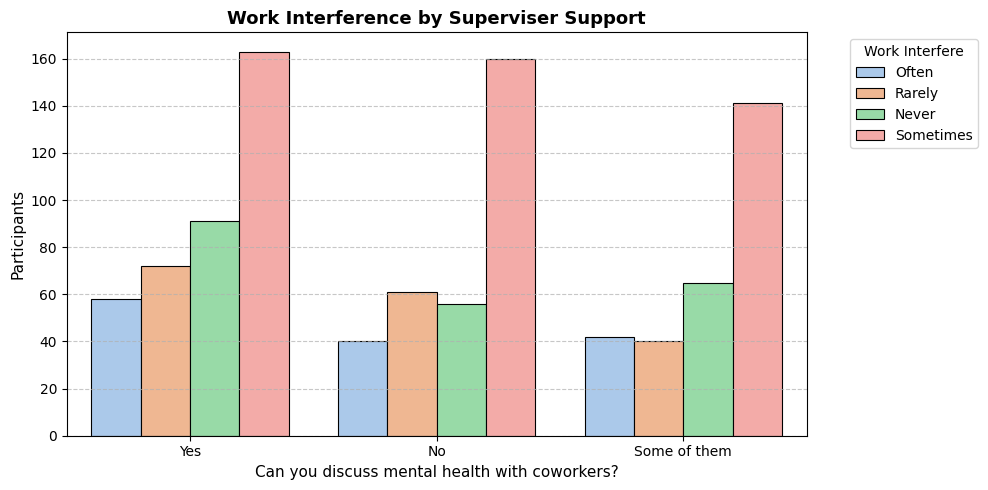

In [54]:
sns.countplot(
    x='supervisor',
    hue='work_interfere',
    data=df,
    palette='pastel',
    edgecolor='black',
    linewidth=0.8
)

plt.title('Work Interference by Supervisor Support', fontsize=13, fontweight='bold')
plt.xlabel('Can you discuss mental health with supervisors?', fontsize=11)
plt.ylabel('Participants', fontsize=11)
plt.legend(title='Work Interfere', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Regardless of the workplace atmosphere and relationships between employees, the impact of mental health problems appears to be almost identical. Only a very small proportion of respondents feel completely comfortable talking to all their coworkers. Relationships at work are selective, as employees tend to choose a few trusted individuals rather than see the entire team as a safe space.

A similar pattern can be observed in relationships with managers, although they sometimes seem to be trusted more than coworkers. Nevertheless, conversations within the workplace do not appear to be enough to resolve mental health problems.

**Gender vs Seeking for help**

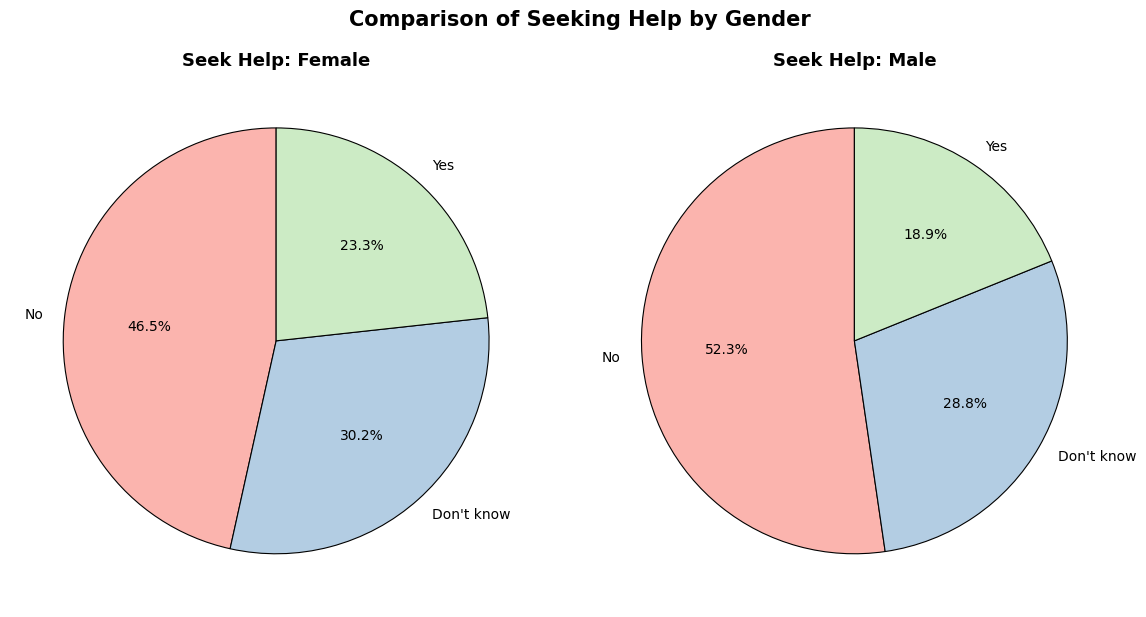

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
genders = ['Female', 'Male']

pastel_colors = ['#fbb4ae', '#b3cde3', '#ccebc5']

for i, gender in enumerate(genders):
    subset =df[df['Gender'] == gender]
    counts = subset['seek_help'].value_counts()
    axes[i].pie(
        counts,
        labels=counts.index,
        autopct='%1.1f%%',
        colors=pastel_colors[:len(counts)],
        wedgeprops={'edgecolor': 'black', 'linewidth': 0.8},
        startangle=90
    )
    axes[i].set_title(f'Seek Help: {gender}', fontsize=13, fontweight='bold')

plt.suptitle('Comparison of Seeking Help by Gender', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

The two pie charts above support my initial assumptions. A significantly higher proportion of women are willing to seek psychological help compared to men. The IT industry is no exception, as this finding reflects a broader global trend.

Unforunatelly, that fact is connected to bigger amount of suicidal death among men rather than among women.

**5. Summary**

The analysis of the 2014 OSMI survey shows that mental health in the IT industry is still a sensitive and unevenly supported topic. Larger companies tend to offer more mental health benefits, but many employees do not know what support is available to them, which suggests a communication problem. Stigma also remains visible: employees are more afraid of the consequences of mental health issues than of physical ones, and women are more likely than men to seek treatment. Other factors, such as employment status or support from coworkers and supervisors, showed no clear effect.


